# Homework 5 - Financial Data Analysis I

by Kun Yang & Fendy Zhong (Group 20)

# Step 1: Read data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
import itertools

In [2]:
data = pd.read_csv('HW4Data.csv', parse_dates=['date'])
data.head()

,date,SPX,VVIX,impl_volatility,impl_strike
0,2024-08-29,5591.96,97.08,0.154164,5452.219
1,2024-08-30,5648.40,93.73,0.141694,5519.684
2,2024-09-03,5528.93,129.79,0.198316,5348.328
3,2024-09-04,5520.07,123.47,0.193275,5344.522
4,2024-09-05,5503.41,115.01,0.197365,5324.533


# Step 2: Merge with vix1m and vix3m

In [4]:
vix1m = pd.read_csv('VIX1M_History.csv', parse_dates=['DATE'])
vix3m = pd.read_csv('VIX3M_History.csv', parse_dates=['DATE'])
vix1m.head()

,DATE,OPEN,HIGH,LOW,CLOSE
0,1990-01-02,17.24,17.24,17.24,17.24
1,1990-01-03,18.19,18.19,18.19,18.19
2,1990-01-04,19.22,19.22,19.22,19.22
3,1990-01-05,20.11,20.11,20.11,20.11
4,1990-01-08,20.26,20.26,20.26,20.26


In [5]:
vix1m = vix1m[['DATE', 'CLOSE']].rename(columns={'DATE': 'date', 'CLOSE': 'VIX1M'})
vix3m = vix3m[['DATE', 'CLOSE']].rename(columns={'DATE': 'date', 'CLOSE': 'VIX3M'})
vix1m.head()

,date,VIX1M
0,1990-01-02,17.24
1,1990-01-03,18.19
2,1990-01-04,19.22
3,1990-01-05,20.11
4,1990-01-08,20.26


In [6]:
mergedData = data.merge(vix1m, on='date', how='left').merge(vix3m, on='date', how='left')
mergedData.head()

,date,SPX,VVIX,impl_volatility,impl_strike,VIX1M,VIX3M
0,2024-08-29,5591.96,97.08,0.154164,5452.219,15.65,18.00
1,2024-08-30,5648.40,93.73,0.141694,5519.684,15.00,17.43
2,2024-09-03,5528.93,129.79,0.198316,5348.328,20.72,21.70
3,2024-09-04,5520.07,123.47,0.193275,5344.522,21.32,22.07
4,2024-09-05,5503.41,115.01,0.197365,5324.533,19.90,20.93


In [7]:
mergedData.isna().sum()

date               0
SPX                0
VVIX               0
impl_volatility    0
impl_strike        0
VIX1M              0
VIX3M              0
dtype: int64

# Step 3: Adding new features

In [8]:
mergedData['diff_iv'] = mergedData['impl_volatility'].diff()                      # 1. day-to-day change in implied vol
mergedData['logret'] = np.log(mergedData['SPX'] / mergedData['SPX'].shift(1))     # 2. daily log return on SPX
mergedData['logret_sq'] = mergedData['logret'] ** 2                               # 3. square of the daily log return
mergedData['diff_vix1m'] = mergedData['VIX1M'].diff()                             # 4. day-to-day change in VIX1M
mergedData['diff_vvix'] = mergedData['VVIX'].diff()                               # 5. day-to-day change in VVIX
mergedData['term_spread'] = mergedData['VIX3M'] - mergedData['VIX1M']             # 6. VIX3M - VIX1M
mergedData['diff_term_spread'] = mergedData['term_spread'].diff()                 # 7. day-to-day change in the term spread

mergedData.head()

,date,SPX,VVIX,impl_volatility,impl_strike,VIX1M,VIX3M,diff_iv,logret,logret_sq,diff_vix1m,diff_vvix,term_spread,diff_term_spread
0,2024-08-29,5591.96,97.08,0.154164,5452.219,15.65,18.00,NaN,NaN,NaN,NaN,NaN,2.35,NaN
1,2024-08-30,5648.40,93.73,0.141694,5519.684,15.00,17.43,-0.012470,0.010042,0.000101,-0.65,-3.35,2.43,0.08
2,2024-09-03,5528.93,129.79,0.198316,5348.328,20.72,21.70,0.056622,-0.021378,0.000457,5.72,36.06,0.98,-1.45
3,2024-09-04,5520.07,123.47,0.193275,5344.522,21.32,22.07,-0.005041,-0.001604,0.000003,0.60,-6.32,0.75,-0.23
4,2024-09-05,5503.41,115.01,0.197365,5324.533,19.90,20.93,0.004090,-0.003023,0.000009,-1.42,-8.46,1.03,0.28


# Step 4: Drop first row

In [9]:
mergedData = mergedData.drop(index=0).reset_index(drop=True)
mergedData.head()

,date,SPX,VVIX,impl_volatility,impl_strike,VIX1M,VIX3M,diff_iv,logret,logret_sq,diff_vix1m,diff_vvix,term_spread,diff_term_spread
0,2024-08-30,5648.40,93.73,0.141694,5519.684,15.00,17.43,-0.012470,0.010042,0.000101,-0.65,-3.35,2.43,0.08
1,2024-09-03,5528.93,129.79,0.198316,5348.328,20.72,21.70,0.056622,-0.021378,0.000457,5.72,36.06,0.98,-1.45
2,2024-09-04,5520.07,123.47,0.193275,5344.522,21.32,22.07,-0.005041,-0.001604,0.000003,0.60,-6.32,0.75,-0.23
3,2024-09-05,5503.41,115.01,0.197365,5324.533,19.90,20.93,0.004090,-0.003023,0.000009,-1.42,-8.46,1.03,0.28
4,2024-09-06,5408.42,119.33,0.213966,5217.335,22.38,22.74,0.016601,-0.017411,0.000303,2.48,4.32,0.36,-0.67


# Step 5: Fit the base model

In [10]:
model = sm.OLS.from_formula('diff_iv ~ logret + logret_sq + diff_vix1m + diff_vvix  + diff_term_spread', data=mergedData).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                diff_iv   R-squared:                       0.951
Model:                            OLS   Adj. R-squared:                  0.950
Method:                 Least Squares   F-statistic:                     943.7
Date:                Wed, 30 Sep 2026   Prob (F-statistic):          2.32e-157
Time:                        22:49:15   Log-Likelihood:                 964.94
No. Observations:                 250   AIC:                            -1918.
Df Residuals:                     244   BIC:                            -1897.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.0002      0.000      0.706      0.481      -0.000       0.001
logret              -0.3339      0.071     -4.681      0.000      -0.474      -0.193
logret_sq           -0.4101      0.551     -0.744      0.457      -1.495       0.675
diff_vix1m           0.0099      0.001     12.345      0.000       0.008       0.012
diff_vvix            0.0001   8.59e-05      1.326      0.186   -5.52e-05       0.000
diff_term_spread     0.0069      0.001      5.016      0.000       0.004       0.010
==============================================================================
Omnibus:                       39.770   Durbin-Watson:                   2.357
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              233.238
Skew:                           0.392   Prob(JB):                     2.25e-51
Kurtosis:                       7.667   Cond. No.                     1.28e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.28e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Comments: The model fits well, with an R-squared of 0.951; however, logret, diff_vix1m, and diff_term_spread are significant, while logret_sq and diff_vvix are not significant at the 5% level.

# Step 6: Residual vs Fitted plot and Q-Q plot

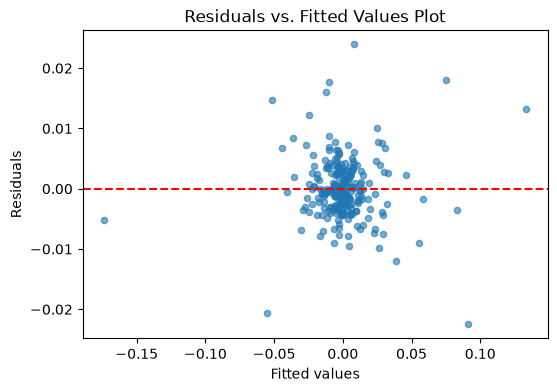

In [11]:
fitted = model.fittedvalues
resid = model.resid

plt.figure(figsize=(6, 4))
plt.scatter(fitted, resid, alpha=0.6, s=20)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title("Residuals vs. Fitted Values Plot")
plt.show()

Comments: From the Residual vs Fitted Value Plot, residuals are centered around 0 with no obvious pattern, suggesting the linear model is appropriate. However, there are extreme points well beyond the main cluster in the plot.

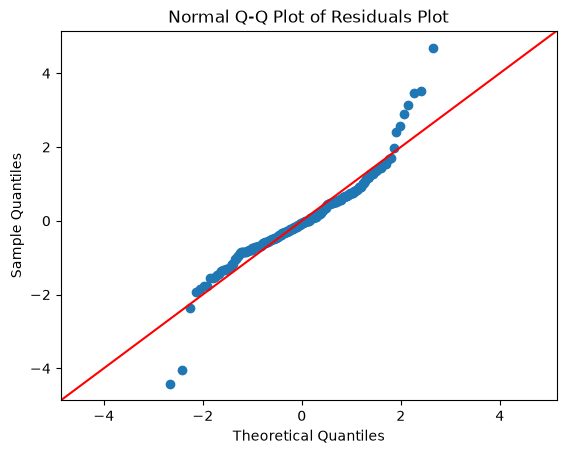

In [12]:
fig = sm.qqplot(resid, line='45', fit=True)
plt.title('Normal Q-Q Plot of Residuals Plot')
plt.show()

In [13]:
import scipy.stats as stats
print(f'Skewness: {stats.skew(resid):.3f}')
print(f'Excess kurtosis: {stats.kurtosis(resid):.3f}')

Skewness: 0.392
Excess kurtosis: 4.667


Comments: From the Q-Q plot, there are clear heavy tails on both sides, so the residuals are not normal. We see skewness of 0.392 and kurtosis of 4.667, so the extreme points have a large impact on the regression model.

# Step 7: Cook's distance

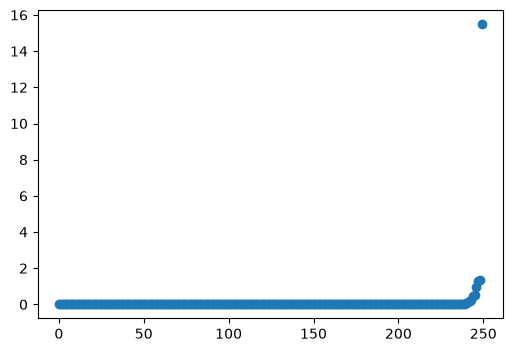

In [14]:
mergedData['cookd'] = model.get_influence().cooks_distance[0]

plt.figure(figsize=[6, 4])
plt.scatter(range(len(mergedData['cookd'])),np.sort(mergedData['cookd']))
plt.show()

In [15]:
mergedData.rank(pct=True).sort_values(by='cookd',ascending=False).head(10)

,date,SPX,VVIX,impl_volatility,impl_strike,VIX1M,VIX3M,diff_iv,logret,logret_sq,diff_vix1m,diff_vvix,term_spread,diff_term_spread,cookd
151,0.608,0.060,0.980,0.980,0.056,0.976,0.972,0.004,1.000,1.000,0.004,0.004,0.020,1.000,1.000
76,0.308,0.432,0.970,0.780,0.408,0.940,0.900,0.988,0.016,0.980,0.996,0.996,0.028,0.008,0.996
148,0.596,0.012,0.984,0.992,0.012,0.992,0.992,1.000,0.004,0.996,1.000,0.992,0.012,0.004,0.992
77,0.312,0.420,0.976,0.820,0.384,0.892,0.896,0.768,0.376,0.120,0.020,0.872,0.136,0.996,0.988
152,0.612,0.020,0.996,0.988,0.020,0.988,0.988,0.996,0.012,0.988,0.988,0.980,0.016,0.044,0.984
154,0.620,0.052,0.940,0.968,0.040,0.968,0.968,0.008,0.844,0.708,0.008,0.008,0.052,0.992,0.980
149,0.600,0.008,0.992,0.996,0.008,0.996,0.996,0.948,0.312,0.244,0.888,0.840,0.008,0.028,0.976
78,0.316,0.496,0.844,0.548,0.500,0.582,0.584,0.024,0.908,0.800,0.012,0.012,0.444,0.984,0.972
150,0.604,0.004,1.000,1.000,0.004,1.000,1.000,0.976,0.072,0.884,0.980,0.984,0.004,0.088,0.968
3,0.016,0.076,0.860,0.752,0.088,0.722,0.708,0.712,0.264,0.332,0.156,0.084,0.292,0.728,0.964


Comments: The sorted Cook's-distance plot has an extreme elbow: one observation is
an order of magnitude more influential than everything else, with $D
\approx 15.5$.

In the percentile ranks, the top few rows are very influential, especially the
observation with the largest log return, squared log return, and
diff_term_spread, all at the 100th percentile.

On that day, Trump announced a pause on reciprocal tariffs, which triggered
a historic relief rally -- the S&P jumped about 9% and implied vols
collapsed. It sits at an extreme corner of the predictor space.

Yes, this is a real concern: a single extraordinary event on one day is
exerting outsized leverage on the fitted coefficients.

# Step 8: VIF

In [16]:
predictors = ['logret', 'logret_sq', 'diff_vix1m', 'diff_vvix', 'diff_term_spread']
y = mergedData['diff_iv']

# Calculate VIF for each predictor directly from the fitted model's design matrix
vif_data = pd.DataFrame()
vif_data["Predictor"] = model.model.exog_names[1:]  # Exclude intercept
vif_data["VIF"] = [variance_inflation_factor(model.model.exog, i) for i in range(1, model.model.exog.shape[1])]
vif_data

,Predictor,VIF
0,logret,6.771254
1,logret_sq,1.048671
2,diff_vix1m,35.248251
3,diff_vvix,3.636989
4,diff_term_spread,14.914810


Comments: As we can see, diff_vix1m and diff_term_spread have very large VIF values, showing strong multicollinearity.

Explanation: `term_spread` is defined as `VIX3M - VIX1M`, so `diff_term_spread = diff_VIX3M - diff_VIX1M`. The 1-month and 3-month VIX are highly correlated.

As a result, `diff_vix1m` and `diff_term_spread` have a lot of overlapping information, so they shouldn't be over-interpreted in isolation here.

# Step 9: Model improvement

Using step-wise, forward-only, and cross-validation approaches to conduct feature selection.

In [17]:
# Step-wise AIC selection

pred = mergedData[predictors]

def fit_ols(cols):
    Xc = sm.add_constant(mergedData[list(cols)]) if cols else sm.add_constant(pd.DataFrame(index=mergedData.index))
    return sm.OLS(y, Xc).fit()

def aic_of(cols):
    return fit_ols(cols).aic

def stepwise_selection_aic(verbose=False):
    included = []
    current_aic = aic_of(included)
    while True:
        changed = False

        # --- forward step: try adding each excluded predictor ---
        excluded = [c for c in pred if c not in included]
        best_aic, best_feature = current_aic, None
        for col in excluded:
            candidate_aic = aic_of(included + [col])
            if candidate_aic < best_aic:
                best_aic, best_feature = candidate_aic, col
        if best_feature is not None:
            included.append(best_feature)
            current_aic = best_aic
            changed = True
            if verbose:
                print(f'+ {best_feature:35s} {current_aic:.3f}')

        # --- backward step: try removing each included predictor ---
        if included:
            best_aic, worst_feature = current_aic, None
            for col in included:
                trial = [c for c in included if c != col]
                candidate_aic = aic_of(trial)
                if candidate_aic < best_aic:
                    best_aic, worst_feature = candidate_aic, col
            if worst_feature is not None:
                included.remove(worst_feature)
                current_aic = best_aic
                changed = True
                if verbose:
                    print(f'- {worst_feature:35s} {current_aic:.3f}')

        if not changed:
            break
    return included, current_aic

aic_selected, aic_score = stepwise_selection_aic(verbose=True)
print(f'\nStepwise-selected predictors: {aic_selected}')


+ diff_vix1m                          -1847.675
+ diff_term_spread                    -1900.673
+ logret                              -1919.627

Stepwise-selected predictors: ['diff_vix1m', 'diff_term_spread', 'logret']


In [18]:
# Forward-only AIC selection 
predictor_chosen = []
remaining_features = list(pred.columns.values)
best_AIC = np.inf

for i in range(1, len(pred.columns) + 1):
    add_feature = False

    for combo in itertools.combinations(remaining_features, 1):
        X_with_ones = sm.add_constant(mergedData[list(combo) + predictor_chosen])
        aic_model = sm.OLS(endog=y, exog=X_with_ones).fit()
        this_AIC = aic_model.aic

        if this_AIC < best_AIC:
            add_feature = True
            best_AIC = this_AIC
            best_feature = combo[0]

    if add_feature:
        predictor_chosen.append(best_feature)
        remaining_features.remove(best_feature)

print('Forward-AIC selected predictors:', np.sort(predictor_chosen))

Forward-AIC selected predictors: ['diff_term_spread' 'diff_vix1m' 'logret']


In [19]:
# Leave-one-out cross-validation, brute-forced over all subsets 
df2 = {}
for k in range(1, len(pred.columns) + 1):
    for combo in itertools.combinations(pred.columns, k):
        X_with_ones = sm.add_constant(mergedData[list(combo)])
        ite_model = sm.OLS(endog=y, exog=X_with_ones).fit()
        levs = OLSInfluence(ite_model).hat_matrix_diag
        df2[str(combo)] = ((ite_model.resid / (1 - levs)) ** 2).sum()

df2 = pd.Series(df2)
print('LOOCV-best predictor subset:', df2.idxmin())

LOOCV-best predictor subset: ('logret', 'diff_vix1m', 'diff_term_spread')


Comment: all three predictor-selection methods -- Step-wise AIC search, forward-only AIC search, and leave-one-out cross-validation -- agree on the same three predictors: `logret`, `diff_vix1m`, `diff_term_spread`.

Handling the influential observation:

Method 1: Use weighted least squares (WLS) with weights $w_i = 1/\text{VIX1M}_i^2$.

By downweighting high-VIX days, WLS automatically discounts that single extraordinary day rather than excluding it.

In [20]:
selected = aic_selected
X_sel = sm.add_constant(mergedData[selected])
weights = 1.0 / (mergedData['VIX1M'] ** 2)

model_wls = sm.WLS(y, X_sel, weights=weights).fit()
model_wls.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            WLS Regression Results                            
==============================================================================
Dep. Variable:                diff_iv   R-squared:                       0.933
Model:                            WLS   Adj. R-squared:                  0.932
Method:                 Least Squares   F-statistic:                     1134.
Date:                Wed, 30 Sep 2026   Prob (F-statistic):          1.13e-143
Time:                        22:50:10   Log-Likelihood:                 1011.6
No. Observations:                 250   AIC:                            -2015.
Df Residuals:                     246   BIC:                            -2001.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.0002      0.000      0.725      0.469      -0.000       0.001
diff_vix1m           0.0094      0.001     14.628      0.000       0.008       0.011
diff_term_spread     0.0057      0.001      4.503      0.000       0.003       0.008
logret              -0.3961      0.063     -6.290      0.000      -0.520      -0.272
==============================================================================
Omnibus:                        9.701   Durbin-Watson:                   2.468
Prob(Omnibus):                  0.008   Jarque-Bera (JB):               14.560
Skew:                           0.240   Prob(JB):                     0.000689
Kurtosis:                       4.080   Cond. No.                         423.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Method 2: FGLS approach.

Instead of weighting by $1/\text{VIX1M}^2$, this method estimates the weights directly from the data: regress $\log(\text{residual}^2)$ from the base model on the chosen predictors (a proxy for how the error variance moves with those predictors), then weight each observation by the inverse of that fitted value.

In [21]:
# Fit weighted least squares (WLS) using an FGLS-estimated weight 
# Since the true error variance is unknown, estimate it with FGLS:
# use log of the squared residuals as a new response
mergedData['log_squared_resid'] = np.log(model.resid**2)

model_fgls = sm.OLS.from_formula('log_squared_resid ~ logret + diff_vix1m + diff_term_spread', data=mergedData).fit()
# Use the fitted values from the FGLS model to estimate the weights.
# model_fgls predicts log(variance), so we exponentiate back to variance
# before inverting to get a proper inverse-variance weight.
fgls_weights = 1 / np.exp(model_fgls.fittedvalues)

model_wls_fgls = sm.WLS.from_formula('diff_iv ~ logret + diff_vix1m + diff_term_spread', data=mergedData, weights=fgls_weights).fit()

model_wls_fgls.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            WLS Regression Results                            
==============================================================================
Dep. Variable:                diff_iv   R-squared:                       0.985
Model:                            WLS   Adj. R-squared:                  0.985
Method:                 Least Squares   F-statistic:                     5400.
Date:                Wed, 30 Sep 2026   Prob (F-statistic):          4.04e-224
Time:                        22:50:14   Log-Likelihood:                 973.89
No. Observations:                 250   AIC:                            -1940.
Df Residuals:                     246   BIC:                            -1926.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.0003      0.000      0.863      0.389      -0.000       0.001
logret              -0.3417      0.068     -5.007      0.000      -0.476      -0.207
diff_vix1m           0.0099      0.001     14.954      0.000       0.009       0.011
diff_term_spread     0.0054      0.001      4.410      0.000       0.003       0.008
==============================================================================
Omnibus:                       44.499   Durbin-Watson:                   2.462
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              219.165
Skew:                           0.564   Prob(JB):                     2.56e-48
Kurtosis:                       7.446   Cond. No.                     1.01e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.01e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [22]:
# Standardized (constant-variance-scale) residuals for each model, for skew/kurtosis/BP checks
std_resid_wls = model_wls.resid * np.sqrt(weights)
std_resid_fgls = model_wls_fgls.resid * np.sqrt(fgls_weights)

bp_ols = sm.stats.diagnostic.het_breuschpagan(resid, model.model.exog)[1]
bp_wls = sm.stats.diagnostic.het_breuschpagan(std_resid_wls, X_sel)[1]
bp_fgls = sm.stats.diagnostic.het_breuschpagan(std_resid_fgls, model_wls_fgls.model.exog)[1]

compare = pd.DataFrame({
    'Model': ['AIC', 'BIC', 'R-squared', 'Residual Std Error', 'Skewness', 'Excess kurtosis', 'Breusch-Pagan p-value'],
    'OLS (base)': [model.aic, model.bic, model.rsquared, model.scale**0.5,
                   stats.skew(resid), stats.kurtosis(resid), bp_ols],
    'WLS (1/VIX1M^2)': [model_wls.aic, model_wls.bic, model_wls.rsquared, model_wls.scale**0.5,
                        stats.skew(std_resid_wls), stats.kurtosis(std_resid_wls), bp_wls],
    'WLS (FGLS)': [model_wls_fgls.aic, model_wls_fgls.bic, model_wls_fgls.rsquared, model_wls_fgls.scale**0.5,
                   stats.skew(std_resid_fgls), stats.kurtosis(std_resid_fgls), bp_fgls],
})
compare

,Model,OLS (base),WLS (1/VIX1M^2),WLS (FGLS)
0,AIC,-1917.875814,-2015.208889,-1939.777962
1,BIC,-1896.747049,-2001.123046,-1925.692118
2,R-squared,0.950832,0.932543,0.985041
3,Residual Std Error,0.005161,0.000231,2.380788
4,Skewness,0.391973,0.240443,0.564077
5,Excess kurtosis,4.666505,1.080031,4.446019
6,Breusch-Pagan p-value,0.000689,0.038396,0.977488


Comment: Both weighting methods improve on the base model. The $1/\text{VIX1M}^2$ weighting gives a better AIC and lower excess kurtosis, while the FGLS approach performs better on the Breusch-Pagan test and R-squared.

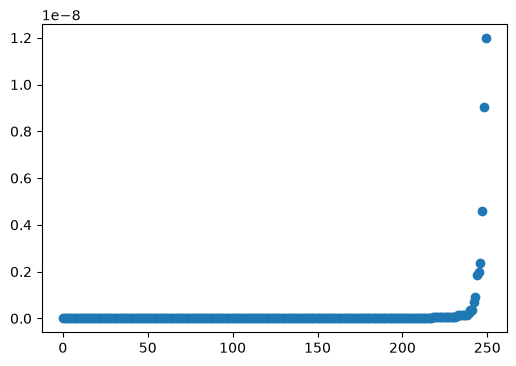

In [25]:
cooks_distances_wls_fgls = OLSInfluence(model_wls_fgls).cooks_distance[0]

plt.figure(figsize=[6,4])
plt.scatter(range(len(cooks_distances_wls_fgls)),np.sort(cooks_distances_wls_fgls))
plt.show()


Comment: The WLS cook's distance plot shows that the influential points have been reduced compared to the OLS model.  WLS handles outliers and heteroskedasticity better with weights.

# Conclusion: We used AIC search (forward and step-wise) and cross-validation to select three predictors. We implemented two different WLS methods to assign a small weight to the extreme value. Both new models showed improvements and addressed issues like multicollinearity and extreme values.